In [1]:
from datasets import load_dataset

ds = load_dataset("openpecha/stt-training-data", split='train').select(range(1))

In [3]:
import requests

response = requests.get(ds[0]["url"])
response.raise_for_status()

# Save to regular WAV file
with open("audio_file.wav", "wb") as f:
    f.write(response.content)

print("Audio saved as audio_file.wav")

Audio saved as audio_file.wav


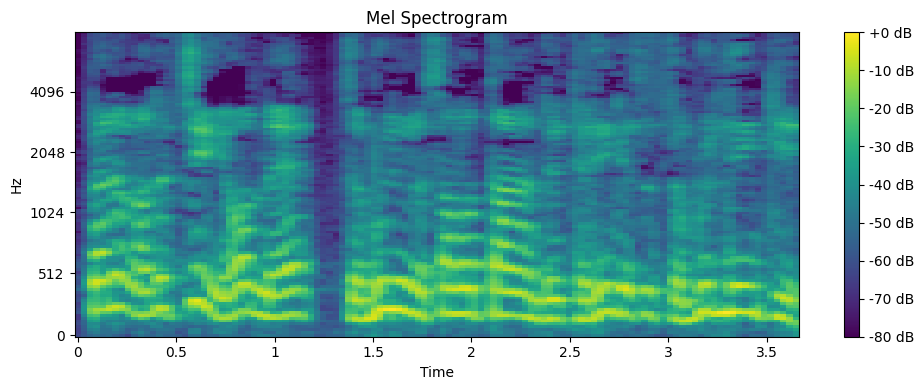

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import librosa

# Load and resample audio using librosa
y, sr = librosa.load('audio_file.wav', sr=16000)

# Create mel spectrogram
S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)

# Convert to log scale (dB)
S_dB = librosa.power_to_db(S, ref=np.max)

# Plot the mel spectrogram
plt.figure(figsize=(10, 4))
librosa.display.specshow(S_dB, sr=sr, x_axis='time', y_axis='mel', 
                        fmax=8000, cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel Spectrogram')
plt.tight_layout()